In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sampling physical quantities with gaussian distribution: direct sampling and Metropolis sampling

In [2]:
def psi(x, sigma):

    return np.exp(-x**2 / (4 * sigma**2))

def d2psi(x, sigma):

    return (x**2 / (4 * sigma**4) - 1 / (2 * sigma**2)) * psi(x, sigma)

def monte_carlo_expectation_values(sigma=1.0, num_samples=1000000, L=5.0):

    x = np.random.uniform(-L, L, num_samples)
    domain_volume = 2.0 * L  # b - a
    
    p_vals = psi(x, sigma)
    psi_sq = p_vals**2
    
    norm_integrand = psi_sq
    x_integrand = x * psi_sq
    
    kin_integrand = -0.5 * p_vals * d2psi(x, sigma)
    
    pot_integrand = 0.5 * (x**2) * psi_sq
    
    norm_integral = (domain_volume / num_samples) * np.sum(norm_integrand)
    x_integral = (domain_volume / num_samples) * np.sum(x_integrand)
    kin_integral = (domain_volume / num_samples) * np.sum(kin_integrand)
    pot_integral = (domain_volume / num_samples) * np.sum(pot_integrand)
    
    mean_x = x_integral / norm_integral
    mean_kinetic_energy = kin_integral / norm_integral
    mean_potential_energy = pot_integral / norm_integral
    
    return mean_x, mean_kinetic_energy, mean_potential_energy

In [3]:
sigma = 1.0

ex_kenergy = 1/(8*sigma**2)
ex_penergy = 0.5*sigma**2

mean_x, e_kin, e_pot = monte_carlo_expectation_values(sigma=sigma, num_samples=2000000, L=6.0*sigma)

print(f"Parameters: sigma = {sigma}")
print(f"First Moment ⟨x⟩:          {mean_x:.6f} expected: 0")
print(f"Kinetic Energy ⟨E_k⟩:      {e_kin:.6f} expected: {ex_kenergy:.6f}")
print(f"Potential Energy ⟨E_p⟩:    {e_pot:.6f} expected: {ex_penergy:.6f}")

Parameters: sigma = 1.0
First Moment ⟨x⟩:          0.001726 expected: 0
Kinetic Energy ⟨E_k⟩:      0.125183 expected: 0.125000
Potential Energy ⟨E_p⟩:    0.499269 expected: 0.500000


In [12]:
N = np.arange(100, 10e5, 1000, dtype='int32')

kenergy = []
penergy = []
momenta = []

for i in N:

    mean_x, e_kin, e_pot = monte_carlo_expectation_values(sigma=sigma, num_samples=i, L=6.0*sigma)
    
    kenergy.append(e_kin)
    penergy.append(e_pot)
    momenta.append(mean_x)
 

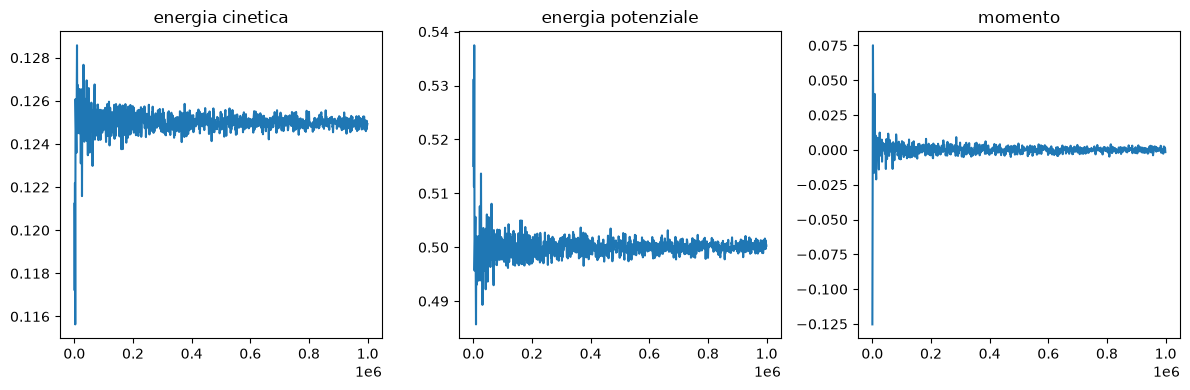

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(12,4))

ax[0].plot(N, kenergy)
ax[0].set_title('energia cinetica')
ax[1].plot(N, penergy)
ax[1].set_title('energia potenziale')
ax[2].plot(N, momenta)
ax[2].set_title('momento')

plt.tight_layout()
plt.show()

In [16]:
err_kinenergy = []
err_potenergy = []

for i in kenergy:

    err_kinenergy.append(i - ex_kenergy)

for j in penergy:

    err_potenergy.append(j - ex_penergy)

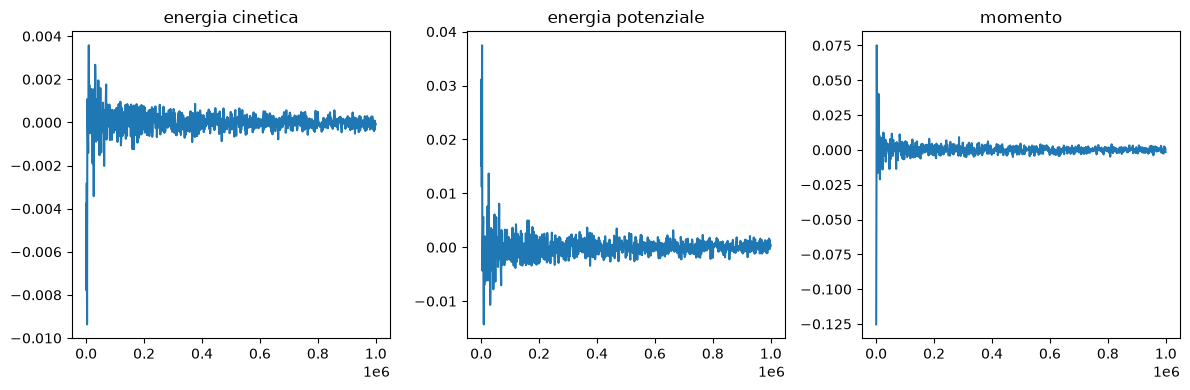

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(12,4))

ax[0].plot(N, err_kinenergy)
ax[0].set_title('energia cinetica')
ax[1].plot(N, err_potenergy)
ax[1].set_title('energia potenziale')
ax[2].plot(N, momenta)
ax[2].set_title('momento')

plt.tight_layout()
plt.show()

In [29]:
def metropolis_expectation_values(sigma=1.0, num_samples=10000, delta=1.5, x0=0.0):
    
    acc = 0.0
    x1 = 0.0
    x2 = 0.0
    x3 = 0.0
    x4 = 0.0
    ekin_sum = 0.0
    epot_sum = 0.0

    exp_current = - (x0**2) / (2.0 * sigma**2)

    for i in range(num_samples):

        local_ekin = -0.5 * ((x0 / (2.0 * sigma**2))**2 - 1.0 / (2.0 * sigma**2))
        local_epot = 0.5 * (x0**2)
        
        ekin_sum += local_ekin
        epot_sum += local_epot
        
        x1 += x0
        x2 += x0**2
        x3 += x0**3
        x4 += x0**4

        rand_step = np.random.rand() - 0.5 
        xp = x0 + delta * rand_step
        
        exp_proposal = - (xp**2) / (2.0 * sigma**2)
        w = np.exp(exp_proposal - exp_current)
        
        if np.random.rand() < w:
            x0 = xp
            exp_current = exp_proposal
            acc += 1.0

    acceptance_rate = acc / num_samples
    mean_x1 = x1 / num_samples
    mean_x2 = x2 / num_samples
    mean_x3 = x3 / num_samples
    mean_x4 = x4 / num_samples
    mean_ekin = ekin_sum / num_samples
    mean_epot = epot_sum / num_samples
    mean_etot = mean_ekin + mean_epot

    return acceptance_rate, mean_x1, mean_x2, mean_x3, mean_x4, mean_ekin, mean_epot, mean_etot

In [30]:
acc_rate, x1, x2, x3, x4, ekin, epot, etot = metropolis_expectation_values()
print(f"Acceptance Rate: {acc_rate * 100:.2f}%")
print(f"⟨x⟩:   {x1:.6f}")
print(f"⟨x²⟩:  {x2:.6f}")
print(f"⟨E_k⟩: {ekin:.6f}")
print(f"⟨E_p⟩: {epot:.6f}")
print(f"⟨E⟩:   {etot:.6f}")

Acceptance Rate: 85.23%
⟨x⟩:   -0.003681
⟨x²⟩:  0.946702
⟨E_k⟩: 0.131662
⟨E_p⟩: 0.473351
⟨E⟩:   0.605013


In [35]:
N = np.arange(100, 10e5, 10000, dtype='int32')

kenergy = []
penergy = []
momenta = []

for i in N:

    acc_rate, x1, x2, x3, x4, ekin, epot, etot = metropolis_expectation_values(num_samples=i)
    
    kenergy.append(ekin)
    penergy.append(epot)
    momenta.append(x1)


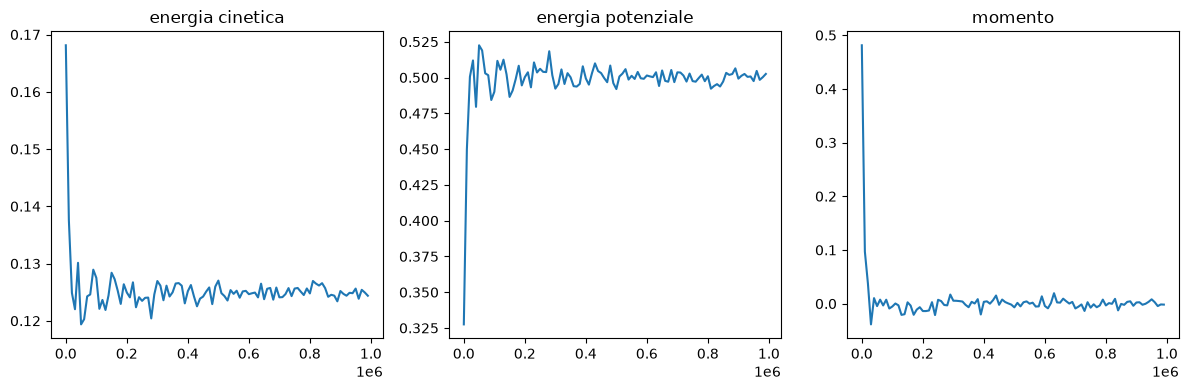

In [36]:
fig, ax = plt.subplots(1, 3, figsize=(12,4))

ax[0].plot(N, kenergy)
ax[0].set_title('energia cinetica')
ax[1].plot(N, penergy)
ax[1].set_title('energia potenziale')
ax[2].plot(N, momenta)
ax[2].set_title('momento')

plt.tight_layout()
plt.show()

In [37]:
err_kinenergy = []
err_potenergy = []

for i in kenergy:

    err_kinenergy.append(i - ex_kenergy)

for j in penergy:

    err_potenergy.append(j - ex_penergy)

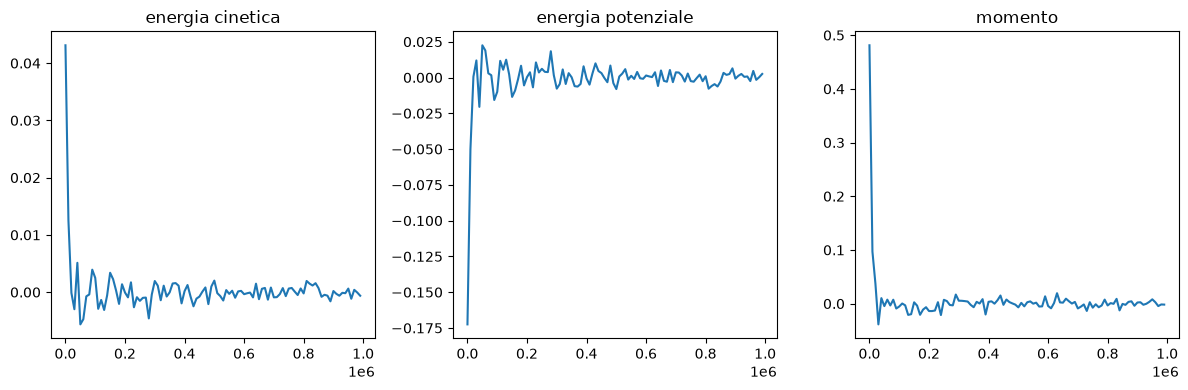

In [38]:
fig, ax = plt.subplots(1, 3, figsize=(12,4))

ax[0].plot(N, err_kinenergy)
ax[0].set_title('energia cinetica')
ax[1].plot(N, err_potenergy)
ax[1].set_title('energia potenziale')
ax[2].plot(N, momenta)
ax[2].set_title('momento')

plt.tight_layout()
plt.show()

In [52]:
l = 30
t = 2

In [55]:
lattice = np.random.randint(2, size=(l,l))
lattice[lattice == 0] = -1
print(lattice)

[[ 1  1 -1  1 -1 -1  1  1 -1 -1 -1  1 -1  1  1  1 -1 -1 -1 -1  1 -1  1 -1
  -1 -1  1 -1 -1 -1]
 [-1  1 -1 -1 -1 -1 -1 -1  1 -1  1 -1  1  1 -1 -1  1  1 -1 -1 -1 -1  1  1
   1  1 -1 -1  1  1]
 [ 1 -1  1  1 -1  1 -1  1 -1  1 -1 -1 -1 -1 -1  1  1 -1 -1 -1  1 -1 -1 -1
  -1 -1  1 -1  1 -1]
 [-1  1  1 -1 -1 -1  1  1 -1  1  1  1  1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1  1
   1 -1 -1  1 -1  1]
 [-1  1  1 -1  1  1 -1 -1 -1 -1  1 -1 -1  1 -1  1  1 -1  1  1 -1  1  1 -1
   1  1  1 -1 -1  1]
 [-1 -1 -1 -1 -1  1  1  1 -1  1 -1  1 -1  1  1 -1  1 -1 -1  1 -1 -1  1  1
   1 -1  1 -1 -1  1]
 [ 1  1 -1  1  1 -1 -1  1 -1  1 -1 -1 -1 -1 -1  1 -1 -1  1  1  1  1 -1  1
   1 -1  1  1 -1 -1]
 [ 1 -1 -1 -1 -1  1 -1 -1  1 -1  1 -1 -1  1 -1  1 -1 -1 -1  1  1  1  1  1
  -1 -1  1  1  1  1]
 [ 1 -1  1 -1  1  1  1  1  1 -1 -1 -1 -1  1  1  1 -1  1  1  1  1 -1  1  1
  -1  1  1  1 -1  1]
 [ 1  1  1 -1  1  1  1  1 -1 -1 -1  1  1 -1 -1  1  1  1  1  1  1  1 -1  1
  -1  1  1 -1  1 -1]
 [ 1 -1  1 -1  1  1 -1  1 -1 -1 -1 -1 -1  1 -1 -1 

In [56]:
magnetization = np.mean(lattice)
print(magnetization)

-0.02


In [57]:
def calculate_energy(lattice, J=1.0):

    neighbors_sum = (
        np.roll(lattice, 1, axis=0) +  
        np.roll(lattice, -1, axis=0) + 
        np.roll(lattice, 1, axis=1) + 
        np.roll(lattice, -1, axis=1)   
    )
    
    total_energy = -0.5 * J * np.sum(lattice * neighbors_sum)
    return total_energy

In [59]:
print(calculate_energy(lattice))

88.0
